# Inverse Physics-Informed Neural Networks
## Estimating Thermal Diffusivity from Sparse and Noisy Temperature Measurements

**Date:** 2026-11-06.

**Goal.** Recover the unknown coefficient $\alpha>0$ of the heat equation from a small set of temperature measurements, while simultaneously reconstructing the temperature field with a neural network.

**Metrics and what counts as done.** The parameter error $E_\alpha$ and the field error $E_u$, evaluated on a held-out grid, for every sparsity and noise setting.

**Evaluation-only rule.** $\alpha_{\text{true}}=0.1$ appears in exactly two places: generating synthetic observations, and computing errors after training. The function `train_pinn` has no access to it, and training settings are chosen from training losses only.

**How to run.** Run all cells from top to bottom. Total runtime is about 45 minutes on a 4-core laptop CPU, and no GPU is needed. All the code is in this notebook; tables and figures are also written to `../results/`.

## 1. Setup

In [1]:
from dataclasses import dataclass, replace
from pathlib import Path
import math, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
import torch
from IPython.display import Markdown, display
from scipy.optimize import minimize_scalar
from torch import nn

ROOT = Path.cwd().parent  # the notebook is run from notebooks/
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

torch.set_num_threads(2)
DTYPE = torch.float64  # double precision: PDE residuals become very small during training
NOTEBOOK_START = time.perf_counter()

ALPHA_TRUE = 0.1  # EVALUATION ONLY: used to generate data and to score results, never in training
DATA_SEED = 42    # seed of the main observation set
SEEDS = [42, 43, 44, 45, 46]  # repeated runs; each seed fixes observations, noise, collocation points and network init
ITERATIONS = 10000
INITIAL_ITERATIONS = 5000

# Colors: categorical for different things, one sequential blue ramp for ordered noise levels
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED = "#0b0b0b", "#52514e"
NOISE_COLORS = {0.0: "#86b6ef", 0.01: "#5598e7", 0.03: "#256abf", 0.05: "#0d366b"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

## 2. Reference solution

**Separation of variables.** Substitute $u(x,t)=X(x)T(t)$ into $u_t=\alpha u_{xx}$ and divide by $\alpha XT$:

$$\frac{T'(t)}{\alpha T(t)}=\frac{X''(x)}{X(x)}=-\lambda .$$

The left side depends only on $t$ and the middle only on $x$, so both equal a constant $-\lambda$.

*Space.* $X''+\lambda X=0$ with $X(0)=X(1)=0$ has nonzero solutions only for $\lambda_n=(n\pi)^2$, $X_n(x)=\sin(n\pi x)$, $n=1,2,\dots$

*Time.* $T'=-\alpha\lambda_n T$ gives $T_n(t)=e^{-\alpha n^2\pi^2 t}$.

*Superposition.* $u(x,t)=\sum_{n\ge1} b_n e^{-\alpha n^2\pi^2 t}\sin(n\pi x)$. The initial condition requires $\sum_n b_n\sin(n\pi x)=\sin(\pi x)$. Since the sines are orthogonal on $[0,1]$, $b_1=1$ and $b_n=0$ for $n\ge2$. Therefore

$$u_{\text{ref}}(x,t)=e^{-\alpha\pi^2 t}\sin(\pi x).$$

The next cell verifies the PDE, the initial condition and the boundary conditions symbolically.

In [2]:
x_s, t_s, a_s = sp.symbols("x t alpha", positive=True)
u_s = sp.exp(-a_s * sp.pi**2 * t_s) * sp.sin(sp.pi * x_s)

checks = pd.DataFrame({
    "check": ["u_t - alpha * u_xx", "u(x, 0) - sin(pi x)", "u(0, t)", "u(1, t)"],
    "sympy result": [
        sp.simplify(sp.diff(u_s, t_s) - a_s * sp.diff(u_s, x_s, 2)),
        sp.simplify(u_s.subs(t_s, 0) - sp.sin(sp.pi * x_s)),
        u_s.subs(x_s, 0),
        u_s.subs(x_s, 1),
    ],
})
display(checks)

,check,sympy result
0,u_t - alpha * u_xx,0
1,"u(x, 0) - sin(pi x)",0
2,"u(0, t)",0
3,"u(1, t)",0


All four expressions are exactly zero, so $u_{\text{ref}}$ satisfies the whole problem.

**Why observations at $t>0$ contain information about $\alpha$.** At $t=0$ the solution is $\sin(\pi x)$ for every $\alpha$, so a measurement there says nothing about it. The coefficient acts only through the decay rate, as the sensitivity of the solution shows:

$$S(x,t)=\frac{\partial u_{\text{ref}}}{\partial\alpha}=-\pi^2 t\,e^{-\alpha\pi^2 t}\sin(\pi x).$$

$S$ vanishes at $t=0$ and at $x=0,1$, because the initial and boundary values do not depend on $\alpha$. $|S|$ is largest at $x=\tfrac12$, $t=1/(\alpha\pi^2)$. For $\alpha_{\text{true}}$ this time is $\approx1.01$, so the most informative measurements lie late in the time window and near the center of the rod. In exact arithmetic one noiseless point with $t>0$, $0<x<1$ fixes $\alpha=-\ln\!\big(y/\sin(\pi x)\big)/(\pi^2t)$.

For noisy data the sensitivity also bounds the achievable accuracy. With independent Gaussian noise of standard deviation $\sigma$, the Cramér–Rao lower bound for an unbiased estimator is

$$\operatorname{std}(\hat\alpha)\ \ge\ \frac{\sigma}{\sqrt{\sum_i S(x_i,t_i)^2}}.$$

This bound is computed below as an evaluation-only benchmark.

## 3. Synthetic observations and evaluation grid

**Reported seed: `DATA_SEED = 42`** for the main set of $N=100$ pairs, with $x_i,t_i$ uniform on $(0,1)$ and $y_i=u_{\text{ref}}(x_i,t_i)$. Repeated runs use seeds 43–46 in the same way.

The design is paired so that each experiment changes one thing:
- the 20- and 50-point sets are the first points of the 100-point set (nested sets);
- for each seed a single standard-normal vector is drawn and scaled by $\sigma$, so noise levels differ only in magnitude.

The evaluation grid has $201\times201$ points and is never used in training.

,x_i,t_i,y_i
0,0.7740,0.9086,0.2659
1,0.4389,0.6997,0.4921
2,0.8586,0.2659,0.3306
3,0.6974,0.9692,0.3127
4,0.0942,0.7788,0.1352
5,0.9756,0.7169,0.0377
6,0.7611,0.4494,0.4377
7,0.7861,0.2722,0.4759


Observations: N = 100, seed = 42
y range: [0.010, 0.904]; evaluation grid: 40401 points


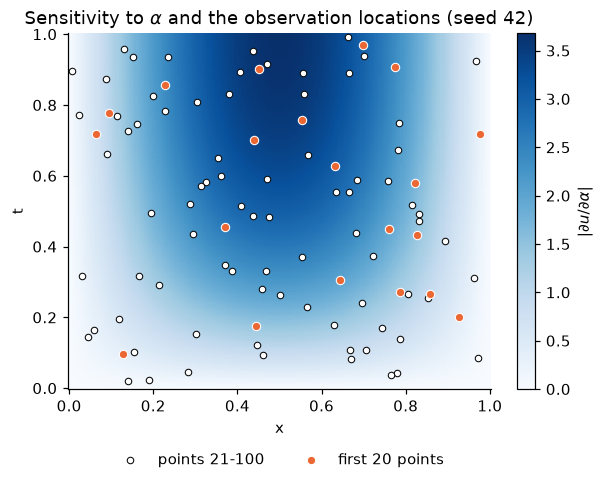

In [3]:
def u_ref(x, t, alpha):
    # Exact solution: called only with ALPHA_TRUE, for data generation and evaluation
    return np.exp(-alpha * np.pi**2 * t) * np.sin(np.pi * x)


def make_observations(seed, n_obs=100, noise_std=0.0):
    # Independent random streams, so changing n_obs or noise_std does not change anything else
    rng = np.random.default_rng([seed, 0])
    x, t = rng.random(100), rng.random(100)
    unit_noise = np.random.default_rng([seed, 2]).standard_normal(100)
    y = u_ref(x, t, ALPHA_TRUE) + noise_std * unit_noise  # amplitude is 1, so sigma = noise_std
    return x[:n_obs], t[:n_obs], y[:n_obs]


# Held-out dense grid, for evaluation only
x_grid, t_grid = np.meshgrid(np.linspace(0, 1, 201), np.linspace(0, 1, 201))
U_REF_GRID = u_ref(x_grid, t_grid, ALPHA_TRUE)

x_obs, t_obs, y_obs = make_observations(DATA_SEED)
display(pd.DataFrame({"x_i": x_obs, "t_i": t_obs, "y_i": y_obs}).head(8).round(4))
print(f"Observations: N = {len(x_obs)}, seed = {DATA_SEED}")
print(f"y range: [{y_obs.min():.3f}, {y_obs.max():.3f}]; evaluation grid: {x_grid.size} points")

# Sensitivity map with the observation points on top
sensitivity = np.abs(np.pi**2 * t_grid * np.exp(-ALPHA_TRUE * np.pi**2 * t_grid) * np.sin(np.pi * x_grid))
fig, ax = plt.subplots(figsize=(6.2, 4.2))
mesh = ax.pcolormesh(x_grid, t_grid, sensitivity, cmap="Blues", shading="auto")
fig.colorbar(mesh, ax=ax, label=r"$|\partial u/\partial\alpha|$")
ax.scatter(x_obs[20:], t_obs[20:], s=18, c="white", edgecolors=INK, linewidths=0.7, label="points 21-100")
ax.scatter(x_obs[:20], t_obs[:20], s=30, c=COLORS[1], edgecolors="white", linewidths=0.7, label="first 20 points")
ax.set(xlabel="x", ylabel="t", title=r"Sensitivity to $\alpha$ and the observation locations (seed 42)")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.savefig(FIGURES / "observations_sensitivity.png")
plt.show()

The points cover the whole domain. Points close to $t=0$ or to the walls carry almost no information about $\alpha$, so the effective amount of data is smaller than $N$, especially for small $N$.

## 4. Network and trainable $\alpha$

**Architecture.** $(x,t)\to$ 3 hidden layers of 32 neurons with $\tanh\to u_\theta$, one scalar output. Inputs are rescaled from $[0,1]$ to $[-1,1]$, which suits $\tanh$.

**Trainable coefficient.** $\alpha=e^{a}$, where $a$ is a trainable scalar updated by the same optimizer as the weights. This keeps $\alpha>0$ automatically and makes steps relative rather than absolute. The starting value is $\alpha_0=1$, ten times larger than the truth, so the result does not benefit from a lucky start.

In [4]:
class InversePINN(nn.Module):
    def __init__(self, hidden_layers=3, hidden_units=32, alpha_init=1.0):
        super().__init__()
        layers = [nn.Linear(2, hidden_units), nn.Tanh()]
        for _ in range(hidden_layers - 1):
            layers += [nn.Linear(hidden_units, hidden_units), nn.Tanh()]
        layers.append(nn.Linear(hidden_units, 1))
        self.net = nn.Sequential(*layers)
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)  # standard initial scale for tanh
                nn.init.zeros_(layer.bias)
        # a is the trainable parameter, alpha = exp(a) > 0 for any value of a
        self.log_alpha = nn.Parameter(torch.tensor(math.log(alpha_init), dtype=DTYPE))

    @property
    def alpha(self):
        return torch.exp(self.log_alpha)

    def forward(self, x, t):
        return self.net(torch.cat([2.0 * x - 1.0, 2.0 * t - 1.0], dim=1))


demo = InversePINN().to(DTYPE)
print(demo.net)
print("Network weights:", sum(p.numel() for p in demo.net.parameters()), "+ 1 trainable scalar a")

Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=32, bias=True)
  (5): Tanh()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Network weights: 2241 + 1 trainable scalar a


## 5. PDE residual and loss

Automatic differentiation gives $u_t$ and $u_{xx}$. `create_graph=True` keeps these derivatives in the computational graph, so the loss can be differentiated with respect to $\theta$ and $a$. The residual is

$$r_\theta(x,t)=\frac{\partial u_\theta}{\partial t}-\alpha\frac{\partial^2u_\theta}{\partial x^2},$$

and the total loss is $L=w_r L_r+w_d L_d+w_i L_i+w_b L_b$, with all weights equal to 1:

| Term | Formula | Meaning |
|---|---|---|
| PDE residual | $L_r=\frac1{N_r}\sum r_\theta(x_j,t_j)^2$ | The field obeys the heat equation at interior collocation points. **It is the only term that links $u_\theta$ and $\alpha$**, so it is the only source of gradient for $a$. |
| Observation fit | $L_d=\frac1{N}\sum\big(u_\theta(x_i,t_i)-y_i\big)^2$ | The field matches the measurements. It holds the actual information about $\alpha$: without it any $\alpha$ is consistent with the other terms. |
| Initial condition | $L_i=\frac1{N_i}\sum\big(u_\theta(x_k,0)-\sin\pi x_k\big)^2$ | Fixes the known starting profile. |
| Boundary condition | $L_b=\frac1{N_b}\sum u_\theta(x_b,t_l)^2,\ x_b\in\{0,1\}$ | Enforces zero temperature at both ends. |

The mechanism is indirect: $L_d$ shapes $u_\theta$ to the measured decay, and $L_r$ then pulls $\alpha$ to the value for which this decay satisfies the PDE.

In [5]:
@dataclass(frozen=True)
class Config:
    iterations: int = ITERATIONS
    lr: float = 1e-3
    lr_final: float = 1e-5          # final learning rate when cosine decay is on
    cosine: bool = True
    lr_alpha: float | None = None   # separate learning rate for a; None means same as lr
    alpha_init: float = 1.0
    n_collocation: int = 1000
    n_initial: int = 100
    n_boundary: int = 100           # split equally between x = 0 and x = 1
    w_pde: float = 1.0
    w_data: float = 1.0
    w_ic: float = 1.0
    w_bc: float = 1.0
    use_physics: bool = True        # False gives a data-only network, a baseline for the field


def to_tensor(values):
    return torch.as_tensor(np.asarray(values), dtype=DTYPE).reshape(-1, 1)


def pde_residual(model, x, t):
    # x and t must have requires_grad=True
    u = model(x, t)
    u_t, u_x = torch.autograd.grad(u.sum(), (t, x), create_graph=True)
    u_xx = torch.autograd.grad(u_x.sum(), x, create_graph=True)[0]
    return u_t - model.alpha * u_xx


def sample_training_points(cfg, seed):
    # Collocation, initial and boundary points are fixed during one run
    rng = np.random.default_rng([seed, 1])
    half = cfg.n_boundary // 2
    x_b = np.r_[np.zeros(half), np.ones(cfg.n_boundary - half)]
    return {
        "x_r": to_tensor(rng.random(cfg.n_collocation)).requires_grad_(True),
        "t_r": to_tensor(rng.random(cfg.n_collocation)).requires_grad_(True),
        "x_i": to_tensor(rng.random(cfg.n_initial)),
        "x_b": to_tensor(x_b),
        "t_b": to_tensor(rng.random(cfg.n_boundary)),
    }


def loss_terms(model, pts, x_obs, t_obs, y_obs, cfg):
    zero = torch.zeros((), dtype=DTYPE)
    pde = (pde_residual(model, pts["x_r"], pts["t_r"]) ** 2).mean() if cfg.use_physics else zero
    data = ((model(x_obs, t_obs) - y_obs) ** 2).mean() if len(x_obs) else zero
    ic = ((model(pts["x_i"], torch.zeros_like(pts["x_i"])) - torch.sin(torch.pi * pts["x_i"])) ** 2).mean()
    bc = (model(pts["x_b"], pts["t_b"]) ** 2).mean()
    return {"pde": pde, "data": data, "ic": ic, "bc": bc}


def train_pinn(x_obs, t_obs, y_obs, cfg, seed):
    # Note: this function receives no alpha_true and no reference solution
    torch.manual_seed(seed)
    model = InversePINN(alpha_init=cfg.alpha_init).to(DTYPE)
    pts = sample_training_points(cfg, seed)
    x_d, t_d, y_d = to_tensor(x_obs), to_tensor(t_obs), to_tensor(y_obs)
    optimizer = torch.optim.Adam([
        {"params": model.net.parameters(), "lr": cfg.lr},
        {"params": [model.log_alpha], "lr": cfg.lr_alpha or cfg.lr},
    ])
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, cfg.iterations, eta_min=cfg.lr_final)
                 if cfg.cosine else None)

    names = ["total", "pde", "data", "ic", "bc", "alpha"]
    log = {name: np.zeros(cfg.iterations) for name in names}
    start = time.perf_counter()
    for i in range(cfg.iterations):
        optimizer.zero_grad()
        terms = loss_terms(model, pts, x_d, t_d, y_d, cfg)
        total = (cfg.w_pde * terms["pde"] + cfg.w_data * terms["data"]
                 + cfg.w_ic * terms["ic"] + cfg.w_bc * terms["bc"])
        total.backward()
        optimizer.step()
        if scheduler:
            scheduler.step()
        log["total"][i] = total.item()
        for name, value in terms.items():
            log[name][i] = value.item()
        log["alpha"][i] = model.alpha.item()
    return model, log, time.perf_counter() - start


def predict_grid(model):
    with torch.no_grad():
        pred = model(to_tensor(x_grid.ravel()), to_tensor(t_grid.ravel()))
    return pred.numpy().reshape(x_grid.shape)


def field_error(pred):
    return np.linalg.norm(pred - U_REF_GRID) / np.linalg.norm(U_REF_GRID)


def alpha_error(alpha_hat):
    return abs(alpha_hat - ALPHA_TRUE) / ALPHA_TRUE  # evaluation only

## 6. Training the baseline

**Starting point.** Adam, constant learning rate $10^{-3}$, 5000 iterations, 1000 collocation points, 100 initial points, 100 boundary points, all weights 1.

**Selection rule.** Settings are compared on training information only: the final total loss, the largest loss in the last 500 iterations (spikes mean the last iterate may land on a bad network), and the drift of $\hat\alpha$ in the last 500 iterations (has it stopped moving?). Errors against $\alpha_{\text{true}}$ are shown in a separate table after the decision.

Four variants run on noiseless data with seeds 42–44:

In [6]:
RUNS = {}  # every finished run is kept here, so shared runs are not repeated within the session


def run_case(n_obs, noise_std, cfg, seed):
    key = (n_obs, noise_std, cfg, seed)
    if key not in RUNS:
        x, t, y = make_observations(seed, n_obs, noise_std)
        model, log, seconds = train_pinn(x, t, y, cfg, seed)
        pred = predict_grid(model)  # evaluation starts only after training has finished
        RUNS[key] = {
            "log": log, "pred": pred, "seconds": seconds, "alpha_hat": log["alpha"][-1],
            "E_alpha": alpha_error(log["alpha"][-1]), "E_u": field_error(pred),
            "final_total": log["total"][-1], "final_data": log["data"][-1],
            "final_constraints": log["pde"][-1] + log["ic"][-1] + log["bc"][-1],
            "max_loss_last500": log["total"][-500:].max(),
            "alpha_drift_last500": np.ptp(log["alpha"][-500:]),
        }
    return RUNS[key]


CFG_FINAL = Config()  # defined here, justified by the table below
VARIANTS = {
    "A: constant lr, 5000 it": Config(iterations=INITIAL_ITERATIONS, cosine=False),
    "B: cosine lr, 5000 it": Config(iterations=INITIAL_ITERATIONS),
    "C: cosine lr, 5000 it, lr_a = 5e-3": Config(iterations=INITIAL_ITERATIONS, lr_alpha=5e-3),
    "D: cosine lr, 10000 it (chosen)": CFG_FINAL,
}
rows = []
for name, cfg in VARIANTS.items():
    for seed in SEEDS[:3]:
        r = run_case(100, 0.0, cfg, seed)
        rows.append({"variant": name, "seed": seed, **{k: r[k] for k in (
            "final_total", "max_loss_last500", "alpha_drift_last500", "E_alpha", "E_u", "seconds")}})
settings = pd.DataFrame(rows)
settings.to_csv(TABLES / "settings_runs.csv", index=False)

selection = settings.groupby("variant", sort=False).agg(
    final_loss_mean=("final_total", "mean"),
    worst_loss_last500=("max_loss_last500", "max"),
    worst_alpha_drift_last500=("alpha_drift_last500", "max"),
    seconds_per_run=("seconds", "mean"),
)
selection.to_csv(TABLES / "settings_selection.csv")
display(selection.style.format({"final_loss_mean": "{:.2e}", "worst_loss_last500": "{:.2e}",
                                "worst_alpha_drift_last500": "{:.1e}", "seconds_per_run": "{:.0f}"}))

,final_loss_mean,worst_loss_last500,worst_alpha_drift_last500,seconds_per_run
variant,,,,
"A: constant lr, 5000 it",1.41e-05,2.41e-03,1.5e-03,19
"B: cosine lr, 5000 it",2.09e-03,5.30e-03,1.1e-03,19
"C: cosine lr, 5000 it, lr_a = 5e-3",4.57e-05,7.55e-05,1.2e-05,19
"D: cosine lr, 10000 it (chosen)",4.39e-06,6.56e-06,2.2e-06,41


**Decision: variant D.** The table above gives the following picture:
- **A (initial settings)** reaches a reasonable final loss ($1.4\cdot10^{-5}$), but the loss spikes up to $2.4\cdot10^{-3}$ within the last 500 iterations and $\hat\alpha$ still drifts by up to $1.5\cdot10^{-3}$. The last iterate could land on a spike, and $\hat\alpha$ has not fully stopped moving.
- **B** removes spikes, but the shrinking learning rate stops training too early: its final loss, $2.1\cdot10^{-3}$, is the worst. The reason is that Adam moves $a$ by about one learning rate per step, and the shortest path from $\alpha_0=1$ to the plateau found by the other variants needs a total travel of $\ln 10\approx2.3$.
- **C** gives $a$ a five times larger learning rate and fixes B's problem, but its final loss, $4.6\cdot10^{-5}$, is still ten times worse than D's.
- **D** has the lowest final loss ($4.4\cdot10^{-6}$), no spikes in the last 500 iterations and a drift of at most $2\cdot10^{-6}$. The cost is twice the time: 37 s instead of 18 s per run.

The same comparison was first run on seeds 0–2 during development, with the same ranking. Errors were visible in those logs, but the choice follows from the loss criteria above.

**Reported changes from the initial settings:** 10000 iterations instead of 5000, and cosine decay of the learning rate from $10^{-3}$ to $10^{-5}$ instead of a constant rate. Variant A stays in this notebook for comparison.

,E_alpha_mean,E_alpha_max,E_u_mean,E_u_max
variant,,,,
"A: constant lr, 5000 it",2.34e-03,6.11e-03,1.34e-03,2.36e-03
"B: cosine lr, 5000 it",2.82e-01,5.45e-01,7.06e-02,1.34e-01
"C: cosine lr, 5000 it, lr_a = 5e-3",4.73e-03,8.00e-03,1.88e-03,2.48e-03
"D: cosine lr, 10000 it (chosen)",2.10e-04,5.65e-04,7.32e-04,1.13e-03


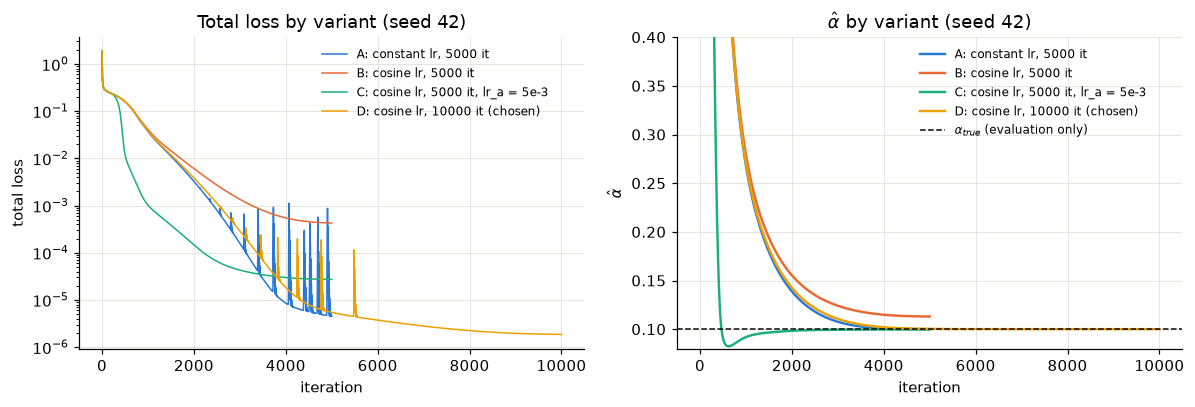

In [7]:
# Shown after the decision: errors were not used to choose the settings
after = settings.groupby("variant", sort=False).agg(
    E_alpha_mean=("E_alpha", "mean"), E_alpha_max=("E_alpha", "max"), E_u_mean=("E_u", "mean"), E_u_max=("E_u", "max"))
display(after.style.format("{:.2e}").set_caption("Evaluation only: errors of the four variants, noiseless data"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, cfg), color in zip(VARIANTS.items(), COLORS):
    log = run_case(100, 0.0, cfg, DATA_SEED)["log"]
    axes[0].semilogy(np.arange(1, len(log["total"]) + 1), log["total"], color=color, lw=1, label=name)
    axes[1].plot(np.arange(1, len(log["alpha"]) + 1), log["alpha"], color=color, label=name)
axes[0].set(xlabel="iteration", ylabel="total loss", title="Total loss by variant (seed 42)")
axes[1].axhline(ALPHA_TRUE, color=INK, ls="--", lw=1, label=r"$\alpha_{true}$ (evaluation only)")
axes[1].set(xlabel="iteration", ylabel=r"$\hat\alpha$", title=r"$\hat\alpha$ by variant (seed 42)", ylim=(0.08, 0.4))
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "settings_comparison.png")
plt.show()

### Baseline run with the chosen settings

**Final configuration.** All changes from the initial setup are in the first three rows of this table.

| Setting | Value | Change? |
|---|---|---|
| Iterations | 10000 | **changed** from 5000 |
| Learning rate | cosine decay $10^{-3}\to10^{-5}$ | **changed** from constant $10^{-3}$ |
| Precision | float64 | added |
| Optimizer | Adam, same schedule for weights and $a$ | initial |
| Points | 1000 collocation, 100 initial, 100 boundary (50 per wall), fixed during a run | initial |
| Loss weights | all 1 | not changed |
| Initial value | $\alpha_0=1$ | our choice |

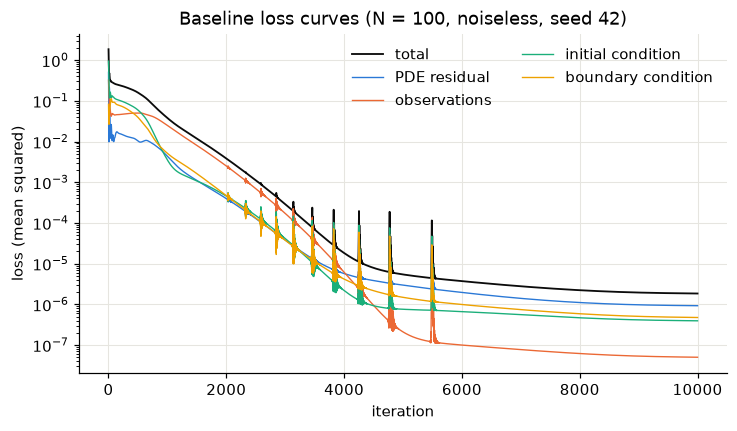

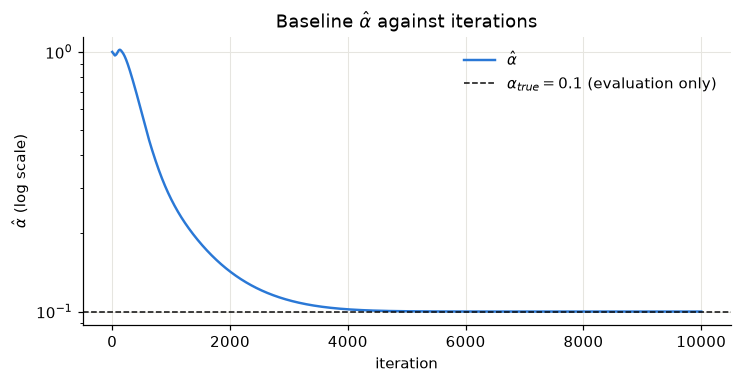

,iteration,total,pde,data,ic,bc,alpha
0,1,1.85e+00,5.02e-01,3.23e-01,9.48e-01,8.23e-02,0.99900
1,1000,3.80e-02,4.36e-03,2.49e-02,3.55e-03,5.15e-03,0.27106
2,2500,1.12e-03,1.29e-04,7.01e-04,1.53e-04,1.33e-04,0.12163
3,5000,5.45e-06,2.98e-06,2.11e-07,7.60e-07,1.49e-06,0.10026
4,7500,2.47e-06,1.23e-06,6.89e-08,5.10e-07,6.57e-07,0.10000
5,10000,1.85e-06,9.29e-07,5.04e-08,3.96e-07,4.77e-07,0.10000


Baseline: alpha_hat = 0.10000, E_alpha = 4.27e-05, E_u = 6.26e-04, training time = 43 s


In [8]:
baseline = run_case(100, 0.0, CFG_FINAL, DATA_SEED)
log = baseline["log"]
iters = np.arange(1, CFG_FINAL.iterations + 1)
pd.DataFrame({"iteration": iters, **log}).iloc[::10].to_csv(TABLES / "baseline_history.csv", index=False)

# Loss curves
fig, ax = plt.subplots(figsize=(7.6, 4))
ax.semilogy(iters, log["total"], color=INK, lw=1.2, label="total")
for (name, label), color in zip(
    {"pde": "PDE residual", "data": "observations", "ic": "initial condition", "bc": "boundary condition"}.items(),
    COLORS):
    ax.semilogy(iters, log[name], color=color, lw=0.9, label=label)
ax.set(xlabel="iteration", ylabel="loss (mean squared)", title="Baseline loss curves (N = 100, noiseless, seed 42)")
ax.legend(ncol=2)
fig.savefig(FIGURES / "baseline_loss_curves.png")
plt.show()

# Alpha estimate against iterations
fig, ax = plt.subplots(figsize=(7.6, 3.4))
ax.plot(iters, log["alpha"], color=COLORS[0], label=r"$\hat\alpha$")
ax.axhline(ALPHA_TRUE, color=INK, ls="--", lw=1, label=r"$\alpha_{true}=0.1$ (evaluation only)")
ax.set(xlabel="iteration", ylabel=r"$\hat\alpha$ (log scale)", yscale="log",
       title=r"Baseline $\hat\alpha$ against iterations")
ax.legend()
fig.savefig(FIGURES / "baseline_alpha.png")
plt.show()

marks = [m for m in (1, 1000, 2500, 5000, 7500, CFG_FINAL.iterations) if m <= CFG_FINAL.iterations]
display(pd.DataFrame({"iteration": marks, **{k: [log[k][m - 1] for m in marks] for k in log}}).style.format(
    {"iteration": "{:d}", "total": "{:.2e}", "pde": "{:.2e}", "data": "{:.2e}", "ic": "{:.2e}", "bc": "{:.2e}", "alpha": "{:.5f}"}))
print(f"Baseline: alpha_hat = {baseline['alpha_hat']:.5f}, E_alpha = {baseline['E_alpha']:.2e}, "
      f"E_u = {baseline['E_u']:.2e}, training time = {baseline['seconds']:.0f} s")

**Reading the curves.** All four loss terms fall together, from about $1.9$ in total to $1.9\cdot10^{-6}$. The spikes up to iteration 5500 are the instability of Adam at a large learning rate; they vanish as the rate decays, which is the purpose of the schedule. $\hat\alpha$ falls from 1 and reaches the plateau around iteration 5000. The final value is $\hat\alpha=0.099996$, so $E_\alpha=4.3\cdot10^{-5}$ and $E_u=6.3\cdot10^{-4}$.

## 7. Observation sparsity

$N=20,50,100$ noiseless measurements, with everything else unchanged, repeated over 5 seeds. Tables report mean and sample standard deviation.

**Baseline for the field.** The data-only network has the same architecture and the same training, but no PDE term ($w_r=0$). It keeps the observations and the initial and boundary conditions. Without $L_r$ there is no gradient for $a$, so this model cannot estimate $\alpha$ at all, but its $E_u$ shows what the physics adds to the field.

**Expectation before seeing the result.** In the noiseless case $\alpha$ should barely depend on $N$, since one parameter is being estimated from exact data. The data-only network should suffer much more from a small $N$.

N,alpha_hat,E_alpha,E_u (PINN),"E_u (data-only, no PDE)"
20,0.10007 ± 0.00011,7.11e-04 ± 1.08e-03,8.50e-04 ± 3.83e-04,7.61e-03 ± 2.06e-03
50,0.10002 ± 0.00003,2.60e-04 ± 2.56e-04,7.11e-04 ± 2.76e-04,5.32e-03 ± 1.37e-03
100,0.10002 ± 0.00004,2.64e-04 ± 3.30e-04,7.88e-04 ± 2.82e-04,4.39e-03 ± 4.71e-04


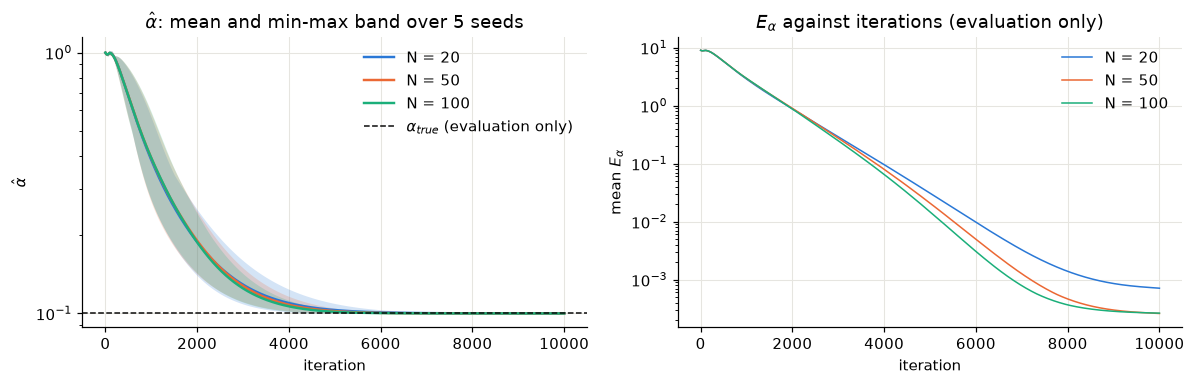

In [9]:
def fmt_pm(values, spec=".2e"):
    return f"{np.mean(values):{spec}} ± {np.std(values, ddof=1):{spec}}" if len(values) > 1 else f"{values[0]:{spec}}"


def collect(n_obs, noise_std, cfg=CFG_FINAL):
    return [run_case(n_obs, noise_std, cfg, seed) for seed in SEEDS]


CFG_DATA_ONLY = replace(CFG_FINAL, use_physics=False)
rows, raw = [], []
for n in (20, 50, 100):
    runs, runs_data = collect(n, 0.0), collect(n, 0.0, CFG_DATA_ONLY)
    rows.append({
        "N": n,
        "alpha_hat": fmt_pm([r["alpha_hat"] for r in runs], ".5f"),
        "E_alpha": fmt_pm([r["E_alpha"] for r in runs]),
        "E_u (PINN)": fmt_pm([r["E_u"] for r in runs]),
        "E_u (data-only, no PDE)": fmt_pm([r["E_u"] for r in runs_data]),
    })
    raw += [{"N": n, "seed": s, "alpha_hat": r["alpha_hat"], "E_alpha": r["E_alpha"], "E_u": r["E_u"], "E_u_data_only": d["E_u"]}
            for s, r, d in zip(SEEDS, runs, runs_data)]
sparsity = pd.DataFrame(rows)
sparsity.to_csv(TABLES / "sparsity_summary.csv", index=False)
pd.DataFrame(raw).to_csv(TABLES / "sparsity_runs.csv", index=False)
display(sparsity.style.hide(axis="index").set_caption(
    "Observation-count experiment: noiseless data, 5 seeds; true alpha used for scoring only"))


def alpha_trace_panel(ax, runs, color, label, zoom_from=0):
    traces = np.stack([r["log"]["alpha"] for r in runs])
    it = np.arange(1, traces.shape[1] + 1)
    ax.fill_between(it, traces.min(0), traces.max(0), color=color, alpha=0.2, lw=0)
    ax.plot(it, traces.mean(0), color=color, label=label)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for n, color in zip((20, 50, 100), COLORS):
    runs = collect(n, 0.0)
    alpha_trace_panel(axes[0], runs, color, f"N = {n}")
    err = np.stack([np.abs(r["log"]["alpha"] - ALPHA_TRUE) / ALPHA_TRUE for r in runs]).mean(0)
    axes[1].semilogy(np.arange(1, len(err) + 1), err, color=color, lw=1, label=f"N = {n}")
axes[0].axhline(ALPHA_TRUE, color=INK, ls="--", lw=1, label=r"$\alpha_{true}$ (evaluation only)")
axes[0].set(xlabel="iteration", ylabel=r"$\hat\alpha$", yscale="log", title=r"$\hat\alpha$: mean and min-max band over 5 seeds")
axes[1].set(xlabel="iteration", ylabel=r"mean $E_\alpha$", title=r"$E_\alpha$ against iterations (evaluation only)")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "sparsity_alpha.png")
plt.show()

**Conclusions.**
- In the noiseless case $\alpha$ is recovered to better than 0.1% on average for every $N$: mean $E_\alpha$ is $7.1\cdot10^{-4}$, $2.6\cdot10^{-4}$, $2.6\cdot10^{-4}$. The worst single run is seed 44 with $N=20$, at 0.26%. This matches the expectation: exact data contain far more information than needed for one scalar.
- The field error of the PINN does not depend on $N$ within the spread, staying near $8\cdot10^{-4}$. It is therefore limited by network training, not by the amount of data.
- The physics term matters for the field: without it $E_u$ is 5.6, 7.5 and 9.0 times larger for $N=100, 50, 20$. The data-only network keeps improving with $N$, whereas the PINN does not need more points here.
- The small effect of $N$ here does not mean that few points are always enough: the next section shows that $N$ becomes important as soon as noise appears.

## 8. Measurement noise

$N=100$; Gaussian noise with $\sigma=0,1,3,5\%$ of the amplitude (1); seeds 42–46, with one noise vector per seed scaled by $\sigma$.

Two benchmarks show how much of the error comes from the data and how much from the PINN. Neither is used in training:
- **Exact-form least squares.** $\hat\alpha_{LS}=\arg\min_\alpha\sum_i\big(y_i-e^{-\alpha\pi^2t_i}\sin\pi x_i\big)^2$. It knows the closed-form solution, which a PINN does not, and it does not use $\alpha_{\text{true}}$.
- **Cramér–Rao bound** at $\alpha_{\text{true}}$ (evaluation only): the best possible standard deviation of an unbiased estimator with these point locations.

**Expectation.** $E_\alpha$ grows about linearly with $\sigma$, reaching a few percent at $\sigma=5\%$ according to the bound.

N,noise %,alpha_hat,"E_alpha, %","E_u, %",L_data,sigma^2,"LS E_alpha, %","CRLB std/alpha, %","E_u of exact formula at alpha_hat, %"
100,0,0.10002 ± 0.00004,0.026 ± 0.033,0.079 ± 0.028,1.19e-07 ± 9.10e-08,0.00e+00,0.000 ± 0.000,0.000,0.011 ± 0.014
100,1,0.10027 ± 0.00037,0.368 ± 0.239,0.220 ± 0.067,1.04e-04 ± 1.17e-05,1.00e-04,0.374 ± 0.238,0.488,0.157 ± 0.102
100,3,0.10076 ± 0.00112,1.098 ± 0.682,0.604 ± 0.223,9.33e-04 ± 1.05e-04,9.00e-04,1.127 ± 0.719,1.463,0.468 ± 0.290
100,5,0.10126 ± 0.00187,1.830 ± 1.137,0.997 ± 0.380,2.59e-03 ± 2.91e-04,2.50e-03,1.883 ± 1.205,2.439,0.778 ± 0.480


N,noise %,alpha_hat,"E_alpha, %","E_u, %",L_data,sigma^2,"LS E_alpha, %","CRLB std/alpha, %","E_u of exact formula at alpha_hat, %"
20,5,0.10419 ± 0.00332,4.186 ± 3.317,1.913 ± 1.231,1.95e-03 ± 4.19e-04,2.50e-03,3.652 ± 3.227,5.951,1.756 ± 1.366


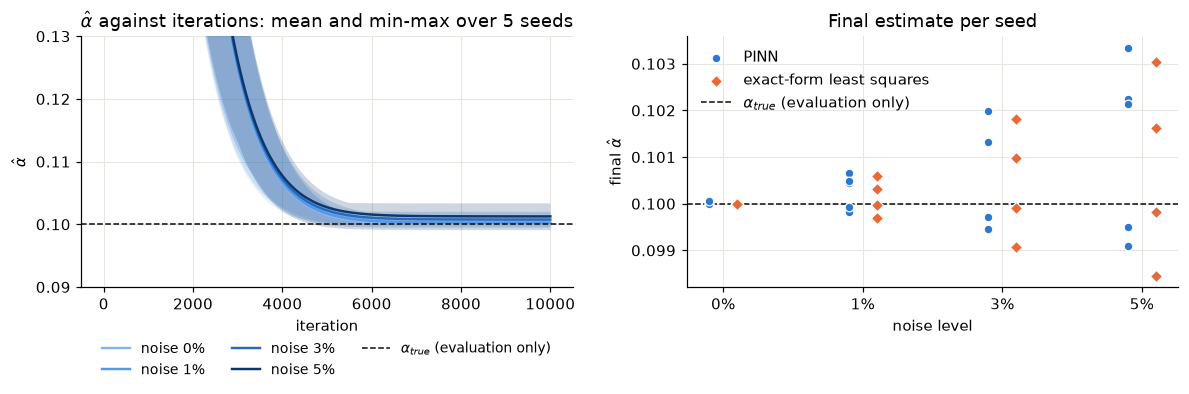

In [10]:
def least_squares_alpha(x, t, y):
    objective = lambda log_a: np.sum((y - u_ref(x, t, np.exp(log_a))) ** 2)
    return float(np.exp(minimize_scalar(objective, bounds=(-7, 2), method="bounded", options={"xatol": 1e-8}).x))


def crlb_relative(x, t, sigma):
    # Evaluation only: uses ALPHA_TRUE to compute the sensitivities
    s = -np.pi**2 * t * np.exp(-ALPHA_TRUE * np.pi**2 * t) * np.sin(np.pi * x)
    return sigma / np.sqrt(np.sum(s**2)) / ALPHA_TRUE


def noise_row(n, sigma):
    runs = collect(n, sigma)
    obs = [make_observations(s, n, sigma) for s in SEEDS]
    ls = np.array([least_squares_alpha(*o) for o in obs])
    plug_in = [field_error(u_ref(x_grid, t_grid, r["alpha_hat"])) for r in runs]
    row = {
        "N": n, "noise %": round(100 * sigma),
        "alpha_hat": fmt_pm([r["alpha_hat"] for r in runs], ".5f"),
        "E_alpha, %": fmt_pm([100 * r["E_alpha"] for r in runs], ".3f"),
        "E_u, %": fmt_pm([100 * r["E_u"] for r in runs], ".3f"),
        "L_data": fmt_pm([r["final_data"] for r in runs], ".2e"),
        "sigma^2": f"{sigma**2:.2e}",
        "LS E_alpha, %": fmt_pm(100 * np.abs(ls - ALPHA_TRUE) / ALPHA_TRUE, ".3f"),
        "CRLB std/alpha, %": f"{100 * np.mean([crlb_relative(o[0], o[1], sigma) for o in obs]):.3f}",
        "E_u of exact formula at alpha_hat, %": fmt_pm(100 * np.array(plug_in), ".3f"),
    }
    per_seed = [{"N": n, "noise": sigma, "seed": s, "alpha_hat": r["alpha_hat"], "E_alpha": r["E_alpha"], "E_u": r["E_u"],
                 "L_data": r["final_data"], "alpha_ls": a_ls} for s, r, a_ls in zip(SEEDS, runs, ls)]
    return row, per_seed


LEVELS = (0.0, 0.01, 0.03, 0.05)
results = [noise_row(100, s) for s in LEVELS]
noise_table = pd.DataFrame([r[0] for r in results])
noise_raw = pd.DataFrame([x for r in results for x in r[1]])
noise_table.to_csv(TABLES / "noise_summary.csv", index=False)
noise_raw.to_csv(TABLES / "noise_runs.csv", index=False)
display(noise_table.style.hide(axis="index").set_caption(
    "Noise experiment: N = 100, 5 seeds; true alpha used for scoring and the CRLB only"))

# Sparsity and noise combined: the hardest setting
cross_row, cross_raw = noise_row(20, 0.05)
cross = pd.DataFrame([cross_row])
cross.to_csv(TABLES / "noise_sparse_summary.csv", index=False)
pd.DataFrame(cross_raw).to_csv(TABLES / "noise_sparse_runs.csv", index=False)
display(cross.style.hide(axis="index").set_caption("Hardest setting: N = 20 and 5% noise, 5 seeds"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for sigma in LEVELS:
    alpha_trace_panel(axes[0], collect(100, sigma), NOISE_COLORS[sigma], f"noise {100 * sigma:.0f}%")
axes[0].axhline(ALPHA_TRUE, color=INK, ls="--", lw=1, label=r"$\alpha_{true}$ (evaluation only)")
axes[0].set(xlabel="iteration", ylabel=r"$\hat\alpha$", ylim=(0.09, 0.13),
            title=r"$\hat\alpha$ against iterations: mean and min-max over 5 seeds")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)

# Per-seed final estimates of the PINN and of the exact-form least squares
for i, sigma in enumerate(LEVELS):
    sub = noise_raw[noise_raw["noise"] == sigma]
    axes[1].scatter(np.full(len(sub), i - 0.1), sub["alpha_hat"], s=32, color=COLORS[0], edgecolors="white",
                    linewidths=0.8, label="PINN" if i == 0 else None, zorder=3)
    axes[1].scatter(np.full(len(sub), i + 0.1), sub["alpha_ls"], s=32, marker="D", color=COLORS[1], edgecolors="white",
                    linewidths=0.8, label="exact-form least squares" if i == 0 else None, zorder=3)
axes[1].axhline(ALPHA_TRUE, color=INK, ls="--", lw=1, label=r"$\alpha_{true}$ (evaluation only)")
axes[1].set_xticks(range(4), [f"{100 * s:.0f}%" for s in LEVELS])
axes[1].set(xlabel="noise level", ylabel=r"final $\hat\alpha$", title="Final estimate per seed")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "noise_alpha.png")
plt.show()

**Conclusions.**
- **Error grows linearly with noise.** Mean $E_\alpha$ is 0.03%, 0.37%, 1.10%, 1.83% for $\sigma=$ 0, 1, 3, 5%. The ratios 1 : 3 : 5 between the noisy levels are expected, since one noise vector per seed is only rescaled.
- **The PINN extracts about as much as the data allow.** Its $E_\alpha$ nearly equals that of least squares with the exact closed-form solution (1.83% vs 1.88% at 5% noise), and the two estimates move together from seed to seed. The mean absolute error of a Gaussian estimator at the Cramér–Rao limit would be $\approx0.8\times2.44\%=1.95\%$ at 5% noise, the same level. So the error at this point is the error of the data, not a defect of the network.
- **No visible overfitting of the noise.** The final $L_d$ stays close to $\sigma^2$: $2.59\cdot10^{-3}$ vs $2.50\cdot10^{-3}$ at 5%. Fitting the noise would push $L_d$ well below $\sigma^2$, and the PDE term prevents that.
- **The field is more accurate than the measurements.** At 5% noise $E_u\approx1.0\%$. Most of it comes from the error in $\hat\alpha$: the exact formula with $\hat\alpha$ inserted already gives 0.78%. In the noiseless case it is different (0.08% vs 0.01%), since there the network approximation error dominates.
- **Bias.** At 5% the mean is $\hat\alpha=0.10126$, above the truth. With a standard deviation of $0.00187$ over 5 seeds this is about 1.5 standard errors, and least squares has the same shift on these noise vectors, so it is not evidence of a systematic bias.
- **Sparsity combined with noise is the hardest case.** With $N=20$ and 5% noise mean $E_\alpha$ rises to 4.2%, and the worst seed reaches 9.8%. Least squares also gets 9.3% on that seed, so the set of 20 points itself is unlucky. The bound rises to 5.95%, which is 2.4 times the value for $N=100$, close to the $\sqrt{5}\approx2.2$ expected from $1/\sqrt N$ (the exact ratio depends on where the points fall).

## 9. Field accuracy on the held-out grid

The grid has $201\times201$ points, which were not used in training, and the errors are

$$E_u=\frac{\lVert u_\theta-u_{\text{ref}}\rVert_2}{\lVert u_{\text{ref}}\rVert_2},\qquad E_\alpha=\frac{|\hat\alpha-\alpha_{\text{true}}|}{\alpha_{\text{true}}}.$$

$\alpha_{\text{true}}$ is used here for evaluation only.

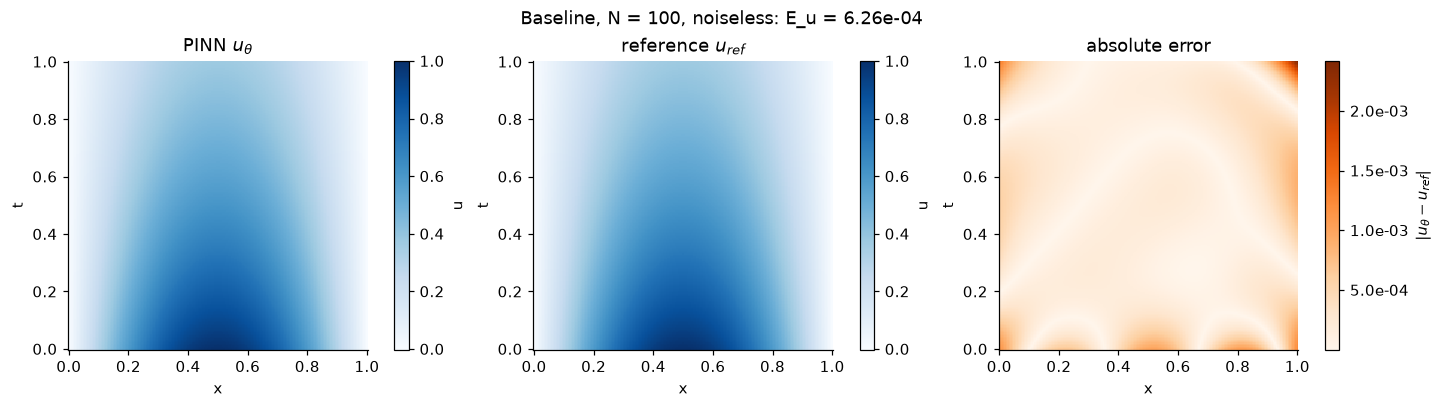

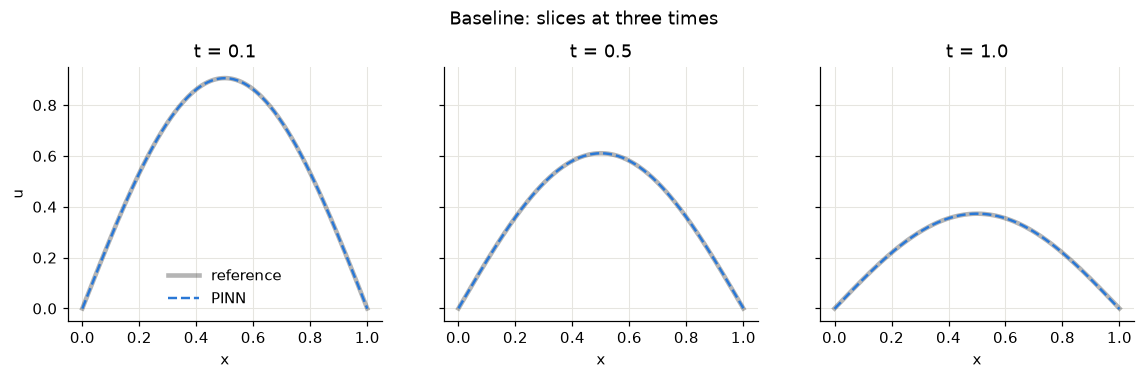

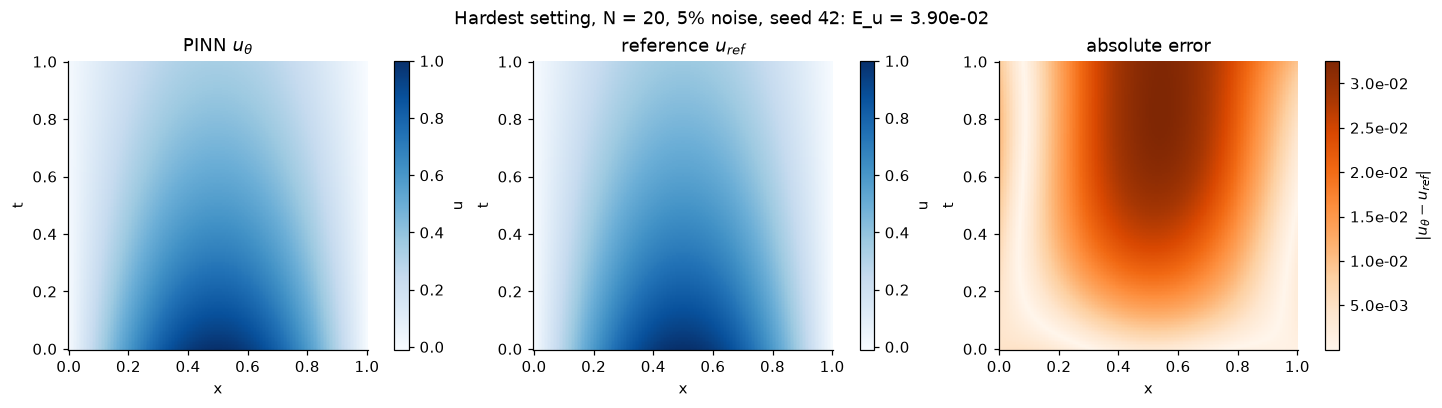

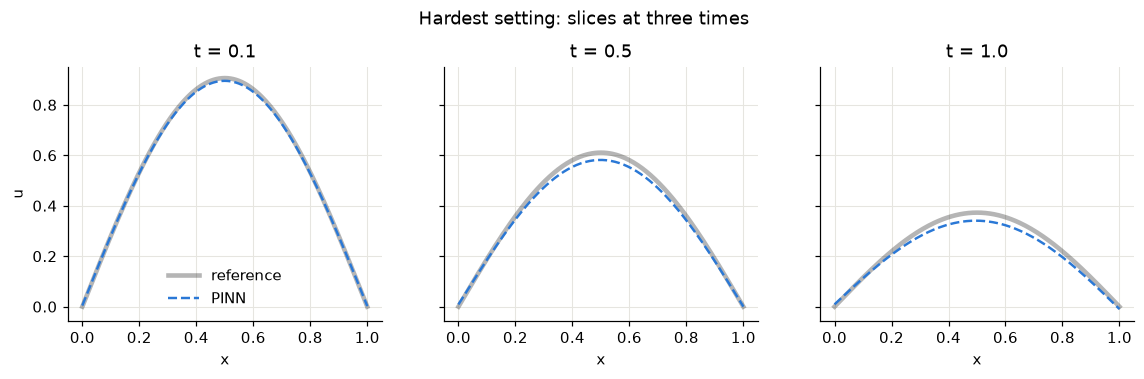

setting,alpha_hat,E_alpha,E_u,max |error|
"baseline, N = 100, 0%",0.10000,4.27e-05,6.26e-04,2.42e-03
"N = 20, 5% noise",0.10985,9.85e-02,3.90e-02,3.25e-02


In [11]:
def field_figure(pred, title, filename):
    # Predicted/reference comparison and an error heatmap
    error = np.abs(pred - U_REF_GRID)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
    vmin, vmax = min(pred.min(), U_REF_GRID.min()), max(pred.max(), U_REF_GRID.max())
    for ax, field, name in zip(axes[:2], (pred, U_REF_GRID), (r"PINN $u_\theta$", r"reference $u_{ref}$")):
        mesh = ax.pcolormesh(x_grid, t_grid, field, cmap="Blues", vmin=vmin, vmax=vmax, shading="auto")
        fig.colorbar(mesh, ax=ax, label="u")
        ax.set(xlabel="x", ylabel="t", title=name)
        ax.grid(False)
    mesh = axes[2].pcolormesh(x_grid, t_grid, error, cmap="Oranges", shading="auto")
    fig.colorbar(mesh, ax=axes[2], format="%.1e", label=r"$|u_\theta-u_{ref}|$")
    axes[2].set(xlabel="x", ylabel="t", title="absolute error")
    axes[2].grid(False)
    fig.suptitle(title)
    fig.savefig(FIGURES / filename)
    plt.show()


def slices_figure(pred, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3), sharey=True)
    for ax, t_value in zip(axes, (0.1, 0.5, 1.0)):
        j = np.argmin(np.abs(t_grid[:, 0] - t_value))
        ax.plot(x_grid[j], U_REF_GRID[j], color=INK, lw=3, alpha=0.3, label="reference")
        ax.plot(x_grid[j], pred[j], color=COLORS[0], ls="--", label="PINN")
        ax.set(xlabel="x", title=f"t = {t_value}")
    axes[0].set_ylabel("u")
    axes[0].legend()
    fig.suptitle(title, y=1.05)
    fig.savefig(FIGURES / filename)
    plt.show()


field_figure(baseline["pred"], f"Baseline, N = 100, noiseless: E_u = {baseline['E_u']:.2e}", "field_baseline.png")
slices_figure(baseline["pred"], "Baseline: slices at three times", "slices_baseline.png")

hard = run_case(20, 0.05, CFG_FINAL, DATA_SEED)
field_figure(hard["pred"], f"Hardest setting, N = 20, 5% noise, seed 42: E_u = {hard['E_u']:.2e}", "field_n20_noise5.png")
slices_figure(hard["pred"], "Hardest setting: slices at three times", "slices_n20_noise5.png")

rows = [{"setting": "baseline, N = 100, 0%", "alpha_hat": baseline["alpha_hat"], "E_alpha": baseline["E_alpha"], "E_u": baseline["E_u"],
         "max |error|": np.abs(baseline["pred"] - U_REF_GRID).max()},
        {"setting": "N = 20, 5% noise", "alpha_hat": hard["alpha_hat"], "E_alpha": hard["E_alpha"], "E_u": hard["E_u"],
         "max |error|": np.abs(hard["pred"] - U_REF_GRID).max()}]
display(pd.DataFrame(rows).style.hide(axis="index").format(
    {"alpha_hat": "{:.5f}", "E_alpha": "{:.2e}", "E_u": "{:.2e}", "max |error|": "{:.2e}"}).set_caption("Seed 42"))

**Conclusions.**
- **Baseline.** $u_\theta$ cannot be told apart from $u_{\text{ref}}$ by eye: $E_u=6.3\cdot10^{-4}$, maximum absolute error $2.4\cdot10^{-3}$. The largest errors lie at the corners of the domain and along $t=0$.
- **Hardest setting, worst seed.** $\hat\alpha=0.1098$ is too large, so the predicted temperature decays too fast: $E_u=3.9\%$, maximum error $3.3\cdot10^{-2}$. The error map now has the shape of the sensitivity map from Section 3 and grows toward late times at the center. The field error here is a direct result of the parameter error.

**Robustness summary**

| Setting | Mean $E_\alpha$ | Mean $E_u$ | Verdict |
|---|---|---|---|
| Noiseless, $N=20$–$100$ | below 0.1% | about 0.08% | robust to sparsity |
| $N=100$, noise 1–5% | 0.37–1.83% | 0.22–1.00% | robust, error near the statistical limit |
| $N=20$, noise 5% | 4.2% (worst 9.8%) | 1.9% (worst 3.9%) | usable, but depends strongly on the point set |

## 10. Identifiability checks

Two extra experiments directly test where the information about $\alpha$ comes from, on noiseless data with seeds 42–44:
1. **Different start**, $\alpha_0=0.01$ and $\alpha_0=5$ with 100 observations. If $\alpha$ is identifiable, the result should not depend on the start.
2. **No observations**, $N=0$, with the same two starts. The PDE, initial and boundary conditions are all kept. For any $\alpha>0$ the problem has an exact solution, so the loss alone should not determine $\alpha$.
3. **Longer training from the far start**, $\alpha_0=5$ with 100 observations and 30000 iterations. This separates a lack of information from a lack of training time, if the 10000-iteration run from this start does not converge.

N,alpha_0,alpha_hat,E_alpha,E_u,final loss
100,0.010000,0.09996 ± 0.00005,4.39e-04 ± 3.54e-04,6.36e-04 ± 2.01e-04,5.47e-06 ± 3.59e-06
100,1.000000,0.10002 ± 0.00003,2.10e-04 ± 3.08e-04,7.32e-04 ± 3.59e-04,4.39e-06 ± 2.33e-06
100,5.000000,0.87328 ± 1.25350,7.73e+00 ± 1.25e+01,2.69e-01 ± 2.94e-01,4.07e-02 ± 5.85e-02
0,0.010000,0.00933 ± 0.00127,9.07e-01 ± 1.27e-02,5.38e-01 ± 1.02e-02,1.17e-06 ± 6.37e-07
0,1.000000,0.43411 ± 0.13400,3.34e+00 ± 1.34e+00,6.17e-01 ± 9.12e-02,1.32e-05 ± 7.87e-06
0,5.000000,2.30086 ± 1.10933,2.20e+01 ± 1.11e+01,9.16e-01 ± 3.44e-02,1.57e-04 ± 1.59e-04


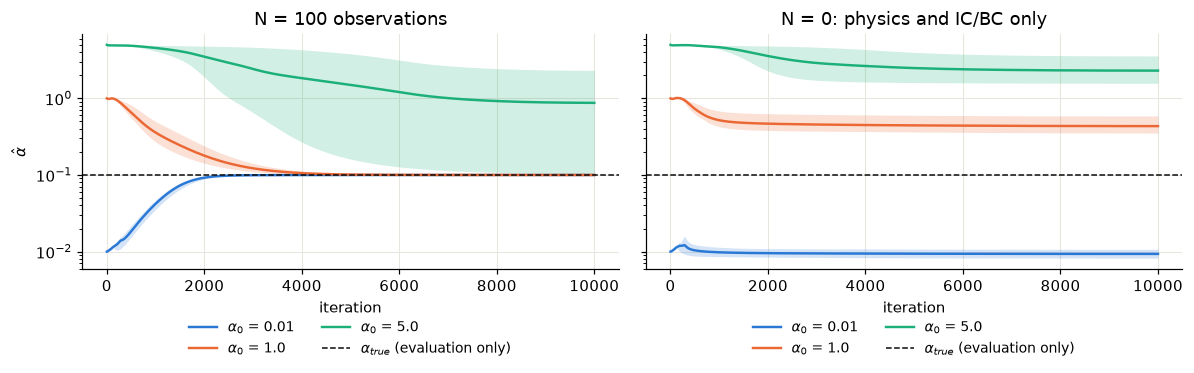

In [12]:
STARTS = (0.01, 1.0, 5.0)
rows, raw = [], []
for n in (100, 0):
    for alpha_init in STARTS:
        cfg = replace(CFG_FINAL, alpha_init=alpha_init)
        runs = [run_case(n, 0.0, cfg, seed) for seed in SEEDS[:3]]
        rows.append({
            "N": n, "alpha_0": alpha_init,
            "alpha_hat": fmt_pm([r["alpha_hat"] for r in runs], ".5f"),
            "E_alpha": fmt_pm([r["E_alpha"] for r in runs]),
            "E_u": fmt_pm([r["E_u"] for r in runs]),
            "final loss": fmt_pm([r["final_total"] for r in runs]),
        })
        raw += [{"N": n, "alpha_0": alpha_init, "seed": s, "alpha_hat": r["alpha_hat"], "E_alpha": r["E_alpha"],
                 "E_u": r["E_u"], "final_loss": r["final_total"]} for s, r in zip(SEEDS, runs)]
ident = pd.DataFrame(rows)
ident.to_csv(TABLES / "identifiability_summary.csv", index=False)
pd.DataFrame(raw).to_csv(TABLES / "identifiability_runs.csv", index=False)
display(ident.style.hide(axis="index").set_caption("Effect of the initial alpha, with and without observations (3 seeds)"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, n, title in zip(axes, (100, 0), ("N = 100 observations", "N = 0: physics and IC/BC only")):
    for alpha_init, color in zip(STARTS, COLORS):
        cfg = replace(CFG_FINAL, alpha_init=alpha_init)
        alpha_trace_panel(ax, [run_case(n, 0.0, cfg, s) for s in SEEDS[:3]], color, rf"$\alpha_0$ = {alpha_init}")
    ax.axhline(ALPHA_TRUE, color=INK, ls="--", lw=1, label=r"$\alpha_{true}$ (evaluation only)")
    ax.set(xlabel="iteration", yscale="log", title=title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)
axes[0].set_ylabel(r"$\hat\alpha$")
fig.tight_layout()
fig.savefig(FIGURES / "identifiability.png")
plt.show()

In [13]:
# Check 3: is a failure from alpha_0 = 5 caused by the data or by the iteration budget?
cfg_short = replace(CFG_FINAL, alpha_init=5.0)
cfg_long = replace(CFG_FINAL, alpha_init=5.0, iterations=3 * CFG_FINAL.iterations)
rows = []
for seed in SEEDS[:3]:
    for label, cfg in (("10000 it", cfg_short), ("30000 it", cfg_long)):
        r = run_case(100, 0.0, cfg, seed)
        rows.append({"seed": seed, "training": label, "alpha_hat": r["alpha_hat"], "final total loss": r["final_total"],
                     "final L_data": r["final_data"], "E_alpha": r["E_alpha"], "E_u": r["E_u"]})
far_start = pd.DataFrame(rows)
far_start.to_csv(TABLES / "far_start_summary.csv", index=False)
display(far_start.style.hide(axis="index").format({"alpha_hat": "{:.5f}", "final total loss": "{:.2e}", "final L_data": "{:.2e}",
                                                   "E_alpha": "{:.2e}", "E_u": "{:.2e}"}).set_caption("Far start, alpha_0 = 5, N = 100, noiseless"))

seed,training,alpha_hat,final total loss,final L_data,E_alpha,E_u
42,10000 it,0.10529,8.01e-05,4.39e-05,5.29e-02,1.38e-02
42,30000 it,0.10001,8.06e-07,1.02e-08,8.20e-05,2.75e-04
43,10000 it,0.19477,1.42e-02,9.72e-03,9.48e-01,2.02e-01
43,30000 it,0.10001,6.89e-07,2.88e-08,8.35e-05,3.10e-04
44,10000 it,2.31977,1.08e-01,6.92e-02,2.22e+01,5.90e-01
44,30000 it,0.10002,2.15e-06,9.86e-08,2.38e-04,7.39e-04


**Conclusions.**
- **$N=100$, $\alpha_0=0.01$ and $\alpha_0=1$** converge to the same value from both sides. Together with the sensitivity analysis this supports identifiability.
- **$N=0$: $\alpha$ is not identifiable without measurements.** The final $\hat\alpha$ stays near its start (0.009, 0.43, 2.30), the loss is small ($10^{-6}$–$10^{-4}$), and $E_u$ is large (54–92%). A low loss alone does not prove that the answer is right: each of these networks approximates the solution of the heat equation for its own wrong $\alpha$.
- **$N=100$, $\alpha_0=5$ does not finish converging within 10000 iterations** for any of the three seeds ($\hat\alpha=0.105$, $0.195$, $2.32$). This is a training failure rather than a lack of information: with 30000 iterations all three seeds reach $\hat\alpha\approx0.1000$, with $E_\alpha\le2.4\cdot10^{-4}$. The result is close to the baseline, so the same minimum is found.
- **The failure can be detected without knowing the truth:** those runs end with a final loss of $8\cdot10^{-5}$, $1.4\cdot10^{-2}$ and $0.11$, against $2$–$6\cdot10^{-6}$ for the same seeds from $\alpha_0=1$. A realistic rule for practice is to run from at least two starts and to reject runs whose loss has not reached the level expected from the noise.

## 11. Discussion and conclusions

**Parameter identifiability.** $\alpha$ is identifiable here because three conditions hold together: measurements at $t>0$ and away from the walls, the known initial profile, and the PDE. The sensitivity $\partial u/\partial\alpha$ vanishes at $t=0$ and at the walls, so points there add nothing. Without measurements the coefficient is not identifiable: every value of $\alpha$ has an exact solution, and the final $\hat\alpha$ just follows its starting value (Section 10). Physically, the coefficient is visible only through the decay rate of the single mode $\sin(\pi x)$, which is why one scalar can be recovered from very little data.

**Sensitivity to noise.** $E_\alpha$ grows linearly with $\sigma$, reaching 1.83% at 5% noise with $N=100$. It stays at the level of the exact-form least-squares estimator and of the Cramér–Rao bound, which scales as $\sigma/\sqrt N$. Reducing $N$ from 100 to 20 at 5% noise raises the mean error to 4.2%, and to 9.8% for the worst point set. The field remains more accurate than the measurements, and at high noise its error mostly follows from the error in $\hat\alpha$.

**Limitations of this approach.**
1. **Training cost and failure risk.** One run takes 37 s, whereas the closed-form least-squares fit takes well under a millisecond and is at least as accurate. A PINN is justified only when no closed form is available, which is not the case in this test problem. Convergence also depends on the start: from $\alpha_0=5$ the budget of 10000 iterations is not enough.
2. **Model assumptions are taken as exact.** The form of the PDE and the initial and boundary conditions are assumed known with no error. Noise is added only to the observations, and a wrong model form was not tested.
3. **The problem is easy.** The solution is one smooth mode with one unknown constant. These results do not carry over automatically to spatially varying coefficients, sharper solutions or several unknowns.
4. **No uncertainty estimate.** A single run gives a point estimate with no error bar. The spread here comes from 5 seeds, so the standard deviations themselves are rough. Loss weights were all 1 and were not studied.

**Conclusion.** The inverse PINN recovers $\alpha$ without being given it: $\hat\alpha=0.10000$ with $E_\alpha=4.3\cdot10^{-5}$ and $E_u=6.3\cdot10^{-4}$ for the baseline. The recovery is robust to sparsity in the noiseless case and degrades in proportion to the noise, close to the statistical limit. The main practical risk is optimization rather than statistics, and it can be detected from the training loss alone.

In [14]:
print(f"Runs trained: {len(RUNS)}; notebook runtime: {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min")

Runs trained: 77; notebook runtime: 47.3 min
